# Actividad Integradora — Unidad 2
**Fundamentos de Ciencia de Datos · TecNM · Ingeniería en Sistemas Computacionales**

**Caso A:** Arquitectura de Software (Monolito vs. Microservicios)
**Pregunta de ingeniería:** ¿La sobrecarga de red en microservicios incrementa la latencia respecto a un monolito?

- Variable cuantitativa (Y): latencia de respuesta HTTP (ms)
- Variable cualitativa (X): tipo de arquitectura (Monolito / Microservicios)

**Equipo:**
- Moreno Rogel Erick
- Avilez Delgado Ismael  
- Bautista Díaz Martín Antonio

**Fecha:** 16/Octubre/2026

**Contenido:** 0. Configuración y dataset · 1. Estadística descriptiva y limpieza · 2. Distribuciones de muestreo y TCL · 3. Intervalos de confianza · 4. Prueba de hipótesis

## 0. Configuración y obtención del dataset

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

SEED = 42
ALPHA = 0.05
ORDEN = ["Monolito", "Microservicios"]
COLORES = {"Monolito": "#2E5597", "Microservicios": "#D9822B"}

# Rutas relativas a la raíz del repositorio (funciona ejecutando desde notebooks/ o desde la raíz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "docs" / "figuras"
for carpeta in (DATA_DIR, FIG_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
RES = {}  # diccionario de resultados que alimenta el reporte técnico (docs/resultados.json)

### Generación sintética justificada (Sección 3, opción 3)
No se dispone de un dataset público con bitácoras pareadas de la misma aplicación desplegada como monolito y como microservicios, por lo que se simula con distribuciones teóricas. Se usa la distribución **Gamma** porque las latencias son positivas y presentan **asimetría positiva** (muchas respuestas rápidas y una cola de respuestas lentas), comportamiento típico de tiempos de respuesta. A cada grupo se le suma un desplazamiento fijo (40 ms / 45 ms) que representa el costo base de procesamiento y red. Se usa el script base del enunciado con `n = 250` por grupo (N = 500 ≥ 400).

In [ ]:
np.random.seed(SEED)
n = 250

lat_monolito = np.random.gamma(shape=2.5, scale=35, size=n) + 40
lat_microserv = np.random.gamma(shape=2.2, scale=40, size=n) + 45

df_original = pd.DataFrame({
    "latencia_ms": np.concatenate([lat_monolito, lat_microserv]),
    "grupo": ["Monolito"] * n + ["Microservicios"] * n,
})
df_original.to_csv(DATA_DIR / "dataset_caso_a.csv", index=False)
print("Dataset guardado en data/dataset_caso_a.csv")

Dataset guardado en data/dataset_caso_a.csv


## Bloque 1 — Estadística descriptiva y limpieza

### 1.1 Carga, tipos de datos y valores ausentes

In [ ]:
df = pd.read_csv(DATA_DIR / "dataset_caso_a.csv")
df["grupo"] = pd.Categorical(df["grupo"], categories=ORDEN)

print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores ausentes por columna:")
print(df.isnull().sum())
print("\nObservaciones por grupo:")
print(df["grupo"].value_counts().reindex(ORDEN))

RES["n_original"] = {g: int((df["grupo"] == g).sum()) for g in ORDEN}
RES["nulos"] = int(df.isnull().sum().sum())

Dimensiones: (500, 2)

Tipos de datos:
latencia_ms     float64
grupo          category
dtype: object

Valores ausentes por columna:
latencia_ms    0
grupo          0
dtype: int64

Observaciones por grupo:
grupo
Monolito          250
Microservicios    250
Name: count, dtype: int64


### 1.2 Detección y remoción de valores atípicos (criterio 1.5 × IQR)
El criterio se aplica **por grupo**, porque cada arquitectura tiene su propia distribución de latencia.

In [ ]:
def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def remover_outliers(datos, col, grupo, k=1.5):
    """Remueve outliers por grupo con el criterio k×IQR. Devuelve (df_limpio, resumen)."""
    mantener = pd.Series(True, index=datos.index)
    filas = []
    for g, sub in datos.groupby(grupo, observed=True):
        lo, hi = limites_iqr(sub[col], k)
        fuera = (sub[col] < lo) | (sub[col] > hi)
        mantener.loc[sub.index[fuera]] = False
        filas.append({"grupo": g, "n_antes": len(sub), "limite_inf": lo, "limite_sup": hi,
                      "n_outliers": int(fuera.sum()), "n_despues": int((~fuera).sum())})
    return datos[mantener].copy(), pd.DataFrame(filas)


df_limpio, resumen_outliers = remover_outliers(df, "latencia_ms", "grupo")
display(resumen_outliers.round(2))

df_limpio.to_csv(DATA_DIR / "dataset_caso_a_limpio.csv", index=False)
RES["outliers"] = resumen_outliers.round(2).to_dict(orient="records")
RES["n_limpio"] = {g: int((df_limpio["grupo"] == g).sum()) for g in ORDEN}
RES["N_limpio"] = int(len(df_limpio))
print(f"\nN tras limpieza: {len(df_limpio)} (≥ 400) · por grupo: {RES['n_limpio']} (≥ 200)")

,grupo,n_antes,limite_inf,limite_sup,n_outliers,n_despues
0,Monolito,250,-5.79,250.65,10,240
1,Microservicios,250,-12.36,260.49,7,243



N tras limpieza: 483 (≥ 400) · por grupo: {'Monolito': 240, 'Microservicios': 243} (≥ 200)


### 1.3 Estadísticos descriptivos por grupo
Asimetría = coeficiente de Fisher–Pearson; curtosis = **exceso** de curtosis (normal = 0). Desviación y varianza muestrales (`ddof = 1`).

In [ ]:
def descriptivos(x):
    return pd.Series({
        "n": len(x), "media": x.mean(), "mediana": x.median(),
        "desv_est (s)": x.std(ddof=1), "varianza (s²)": x.var(ddof=1),
        "asimetria": stats.skew(x), "curtosis (exceso)": stats.kurtosis(x),
    })


desc = df_limpio.groupby("grupo", observed=True)["latencia_ms"].apply(descriptivos).unstack().loc[ORDEN]
display(desc.round(3))
RES["descriptivos"] = {g: {k: float(v) for k, v in desc.loc[g].items()} for g in ORDEN}

,n,media,mediana,desv_est (s),varianza (s²),asimetria,curtosis (exceso)
grupo,,,,,,,
Monolito,240.0,123.200,117.012,43.529,1894.787,0.616,-0.159
Microservicios,243.0,124.614,113.969,48.204,2323.634,0.770,-0.094


### 1.4 Histogramas con KDE y diagramas de caja comparativos

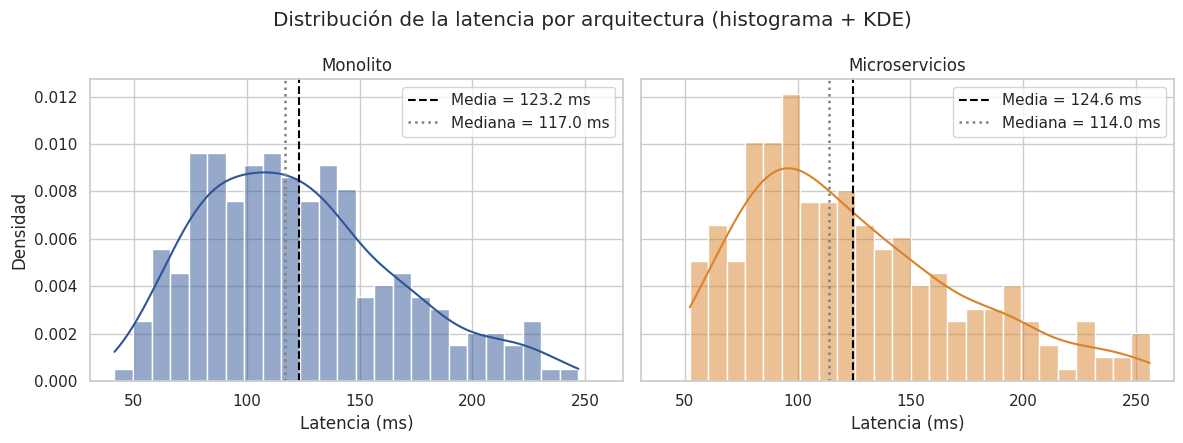

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, g in zip(axes, ORDEN):
    x = df_limpio.loc[df_limpio["grupo"] == g, "latencia_ms"]
    sns.histplot(x, bins=25, kde=True, stat="density", color=COLORES[g], ax=ax)
    ax.axvline(x.mean(), color="black", ls="--", lw=1.5, label=f"Media = {x.mean():.1f} ms")
    ax.axvline(x.median(), color="gray", ls=":", lw=1.8, label=f"Mediana = {x.median():.1f} ms")
    ax.set_title(g)
    ax.set_xlabel("Latencia (ms)")
    ax.legend()
axes[0].set_ylabel("Densidad")
plt.suptitle("Distribución de la latencia por arquitectura (histograma + KDE)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_hist_kde.png", dpi=150)
plt.show()

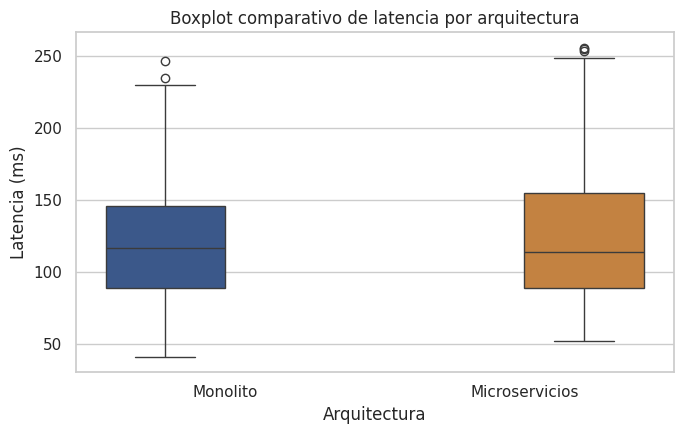

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df_limpio, x="grupo", y="latencia_ms", order=ORDEN, hue="grupo",
            palette=COLORES, legend=False, ax=ax)
ax.set_title("Boxplot comparativo de latencia por arquitectura")
ax.set_xlabel("Arquitectura")
ax.set_ylabel("Latencia (ms)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_boxplot.png", dpi=150)
plt.show()

**Interpretación.** Ambas distribuciones presentan **asimetría positiva** (0.62 en Monolito y 0.77 en Microservicios): la media (123.2 y 124.6 ms) queda por encima de la mediana (117.0 y 114.0 ms) porque una cola de respuestas lentas jala el promedio hacia la derecha. La curtosis en exceso es ligeramente negativa (≈ −0.16 y −0.09), es decir, colas similares a las de una normal una vez depurados los atípicos. Microservicios muestra **mayor dispersión** (s = 48.2 ms vs. 43.5 ms; varianza 2,324 vs. 1,895 ms²), lo que se aprecia en su caja y bigotes más amplios. Los 17 atípicos removidos (10 en Monolito y 7 en Microservicios, el 3.4 % del total) estaban todos en la cola superior (los límites inferiores son negativos), lo que confirma el sesgo a la derecha. Las dos distribuciones se traslapan casi por completo y sus medias son muy cercanas; esto se contrasta formalmente en los Bloques 3 y 4.

## Bloque 2 — Distribuciones de muestreo y Teorema Central del Límite

In [ ]:
# 2.1 Muestra global de la métrica (ambos grupos, ya depurada)
muestra_global = df_limpio["latencia_ms"].to_numpy()
N_GLOBAL = len(muestra_global)
s_global = muestra_global.std(ddof=1)
print(f"N global = {N_GLOBAL} · media = {muestra_global.mean():.3f} ms · s = {s_global:.3f} ms")
print(f"Asimetría de la muestra global: {stats.skew(muestra_global):.3f}")

N global = 483 · media = 123.911 ms · s = 45.898 ms
Asimetría de la muestra global: 0.712


In [ ]:
# 2.2 Remuestreo con reemplazo: k = 1000 muestras para cada n
K = 1000
TAMANOS = [5, 15, 30, 60]
rng = np.random.default_rng(SEED)

medias_muestrales = {
    n_: rng.choice(muestra_global, size=(K, n_), replace=True).mean(axis=1)
    for n_ in TAMANOS
}

filas = []
for n_ in TAMANOS:
    m = medias_muestrales[n_]
    se_emp = m.std(ddof=1)
    se_teo = s_global / np.sqrt(n_)
    filas.append({
        "n": n_, "media de medias": m.mean(), "SE empírico": se_emp, "SE teórico (s/√n)": se_teo,
        "diferencia relativa (%)": 100 * (se_emp - se_teo) / se_teo,
        "asimetría de medias": stats.skew(m), "Shapiro-Wilk p": stats.shapiro(m).pvalue,
    })
tabla_tcl = pd.DataFrame(filas).set_index("n")
display(tabla_tcl.round(4))
RES["tcl"] = [{"n": int(n_), **{k: float(v) for k, v in tabla_tcl.loc[n_].items()}} for n_ in TAMANOS]
RES["tcl_meta"] = {"K": K, "N_global": int(N_GLOBAL), "s_global": float(s_global),
                   "media_global": float(muestra_global.mean()), "asimetria_global": float(stats.skew(muestra_global))}

,media de medias,SE empírico,SE teórico (s/√n),diferencia relativa (%),asimetría de medias,Shapiro-Wilk p
n,,,,,,
5,123.8269,20.4536,20.5264,-0.3546,0.2871,0.0000
15,123.6494,11.4950,11.8509,-3.0032,0.2164,0.0115
30,123.6481,8.5144,8.3799,1.6054,0.0877,0.0293
60,123.7490,6.0550,5.9255,2.1859,0.2070,0.0141


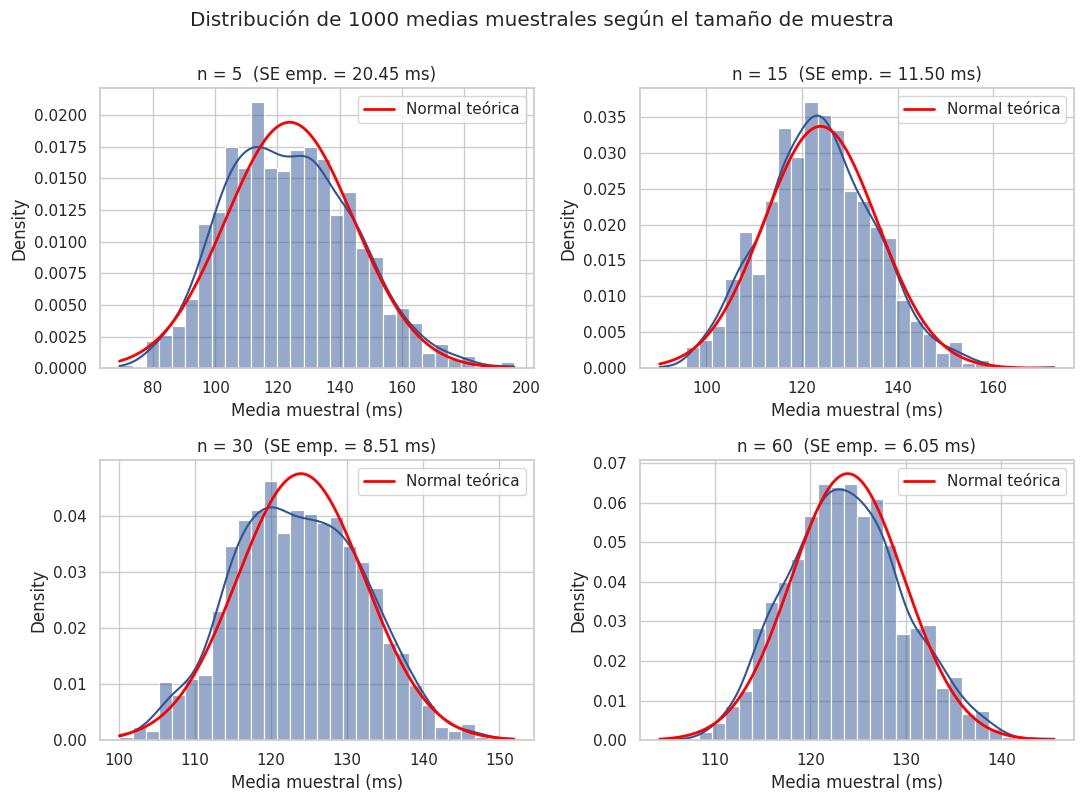

In [ ]:
# 2.3 Cuadrícula 2×2 con las distribuciones de las medias muestrales
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=False)
for ax, n_ in zip(axes.ravel(), TAMANOS):
    m = medias_muestrales[n_]
    sns.histplot(m, bins=30, kde=True, stat="density", color="#2E5597", ax=ax)
    xs = np.linspace(m.min(), m.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, muestra_global.mean(), s_global / np.sqrt(n_)),
            color="red", lw=2, label="Normal teórica")
    ax.set_title(f"n = {n_}  (SE emp. = {m.std(ddof=1):.2f} ms)")
    ax.set_xlabel("Media muestral (ms)")
    ax.legend()
plt.suptitle(f"Distribución de {K} medias muestrales según el tamaño de muestra", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_tcl_grid.png", dpi=150)
plt.show()

**Verificación de σ_x̄ y convergencia a la normalidad.** El error estándar empírico coincide con el teórico s/√n con diferencias relativas de entre −3.0 % y +2.2 %, y disminuye conforme crece n (≈ 20.5 ms con n = 5 hasta ≈ 6.1 ms con n = 60), tal como predice la regla de la raíz cuadrada; las diferencias residuales corresponden a ruido de simulación con K = 1,000.

La población es asimétrica (γ = 0.71), pero la asimetría de las medias muestrales se reduce: la teoría predice γ/√n ≈ 0.32, 0.18, 0.13 y 0.09 para n = 5, 15, 30 y 60 (observado: 0.29, 0.22, 0.09 y 0.21; el error de muestreo de la asimetría con K = 1,000 es ≈ 0.08). En la cuadrícula, los histogramas se ajustan progresivamente a la curva normal teórica (roja). La prueba de Shapiro-Wilk aún rechaza normalidad exacta (p < 0.05), pero con 1,000 medias es muy sensible a desviaciones mínimas; la asimetría remanente es leve. **Conclusión:** la distribución muestral de la media converge a la normal (Teorema Central del Límite) y, desde n ≈ 30, la aproximación es adecuada para fines de inferencia; con N = 483 en los bloques siguientes la normalidad de x̄ está bien justificada.

## Bloque 3 — Estimación por intervalos de confianza

### 3.1 IC para la media poblacional general (μ) al 90 %, 95 % y 99 %

**Justificación de la distribución (t-Student):** la desviación estándar poblacional σ es **desconocida** y se estima con la muestra (s), por lo que el estadístico $(\bar{x}-\mu)/(s/\sqrt{n})$ sigue una distribución **t-Student con n − 1 grados de libertad**. Aunque la población es asimétrica (Gamma), el Teorema Central del Límite (Bloque 2) garantiza que la distribución de $\bar{x}$ es aproximadamente normal con N grande. Con N ≈ 500 los cuantiles t y Z son prácticamente idénticos; se reportan ambos para evidenciarlo.

In [ ]:
def ic_media(x, confianza, dist="t"):
    """IC bilateral para la media. dist='t' (σ desconocida) o 'z'."""
    n_ = len(x)
    xbar = x.mean()
    se = x.std(ddof=1) / np.sqrt(n_)
    alfa = 1 - confianza
    crit = stats.t.ppf(1 - alfa / 2, df=n_ - 1) if dist == "t" else stats.norm.ppf(1 - alfa / 2)
    return xbar - crit * se, xbar + crit * se, crit, se


filas = []
for conf in (0.90, 0.95, 0.99):
    lo_t, hi_t, crit_t, se = ic_media(muestra_global, conf, "t")
    lo_z, hi_z, crit_z, _ = ic_media(muestra_global, conf, "z")
    filas.append({"confianza": f"{conf:.0%}", "t crítico": crit_t, "IC t (inf)": lo_t, "IC t (sup)": hi_t,
                  "amplitud t": hi_t - lo_t, "z crítico": crit_z, "IC z (inf)": lo_z, "IC z (sup)": hi_z})
tabla_ic = pd.DataFrame(filas).set_index("confianza")
display(tabla_ic.round(3))
RES["ic_media"] = {idx: {k: float(v) for k, v in row.items()} for idx, row in tabla_ic.iterrows()}
RES["ic_media_se"] = float(se)

,t crítico,IC t (inf),IC t (sup),amplitud t,z crítico,IC z (inf),IC z (sup)
confianza,,,,,,,
90%,1.648,120.470,127.353,6.884,1.645,120.476,127.347
95%,1.965,119.808,128.015,8.207,1.960,119.818,128.005
99%,2.586,118.511,129.312,10.802,2.576,118.532,129.291


### 3.2 IC del 95 % para la diferencia de medias (μ₁ − μ₂)
Se define **μ₁ = Microservicios** y **μ₂ = Monolito**, de modo que μ₁ − μ₂ > 0 significa que microservicios es más lento.
Primero se verifica la homogeneidad de varianzas con la **prueba de Levene** (H₀: σ₁² = σ₂²). Se usa la versión por defecto de SciPy (`center='median'`, variante de Brown–Forsythe), más robusta ante distribuciones asimétricas como la presente.

In [ ]:
x_micro = df_limpio.loc[df_limpio["grupo"] == "Microservicios", "latencia_ms"].to_numpy()
x_mono = df_limpio.loc[df_limpio["grupo"] == "Monolito", "latencia_ms"].to_numpy()

lev_stat, lev_p = stats.levene(x_micro, x_mono)
varianzas_iguales = lev_p > ALPHA
print(f"Levene: estadístico W = {lev_stat:.4f}, p-value = {lev_p:.4f}")
print("→ No se rechaza H0: varianzas homogéneas → t de Student con varianza combinada (pooled)"
      if varianzas_iguales else
      "→ Se rechaza H0: varianzas heterogéneas → corrección de Welch")
RES["levene"] = {"W": float(lev_stat), "p": float(lev_p), "varianzas_iguales": bool(varianzas_iguales)}

Levene: estadístico W = 1.8419, p-value = 0.1754
→ No se rechaza H0: varianzas homogéneas → t de Student con varianza combinada (pooled)


In [ ]:
def ic_diferencia(x1, x2, confianza=0.95, varianzas_iguales=True):
    """IC bilateral para μ1 − μ2. Devuelve (inf, sup, diff, se, gl, método)."""
    n1, n2 = len(x1), len(x2)
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    diff = x1.mean() - x2.mean()
    if varianzas_iguales:
        gl = n1 + n2 - 2
        sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / gl
        se = np.sqrt(sp2 * (1 / n1 + 1 / n2))
        metodo = "Student (varianza combinada)"
    else:
        se = np.sqrt(v1 / n1 + v2 / n2)
        gl = se**4 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))  # Welch–Satterthwaite
        metodo = "Welch"
    crit = stats.t.ppf(1 - (1 - confianza) / 2, gl)
    return diff - crit * se, diff + crit * se, diff, se, gl, metodo


lo, hi, diff, se_diff, gl, metodo = ic_diferencia(x_micro, x_mono, 0.95, varianzas_iguales)
print(f"Método: {metodo}")
print(f"Diferencia observada (Micro − Mono) = {diff:.3f} ms · SE = {se_diff:.3f} · gl = {gl:.1f}")
print(f"IC 95% para μ1 − μ2 = ({lo:.3f}, {hi:.3f}) ms")

# Verificación cruzada contra SciPy
ic_scipy = stats.ttest_ind(x_micro, x_mono, equal_var=varianzas_iguales).confidence_interval(0.95)
print(f"Verificación SciPy: ({ic_scipy.low:.3f}, {ic_scipy.high:.3f})")
assert np.allclose([lo, hi], [ic_scipy.low, ic_scipy.high], atol=1e-6)

# Comparación con el método alternativo (análisis de sensibilidad)
lo_alt, hi_alt, *_ = ic_diferencia(x_micro, x_mono, 0.95, not varianzas_iguales)
print(f"Método alternativo ({'Welch' if varianzas_iguales else 'pooled'}): ({lo_alt:.3f}, {hi_alt:.3f})")

cero_en_ic = bool(lo <= 0 <= hi)
print(f"\n¿0 ∈ IC? {cero_en_ic}")
RES["ic_diferencia"] = {"metodo": metodo, "diff": float(diff), "se": float(se_diff), "gl": float(gl),
                        "inf": float(lo), "sup": float(hi), "cero_en_ic": cero_en_ic,
                        "alt_inf": float(lo_alt), "alt_sup": float(hi_alt)}

Método: Student (varianza combinada)
Diferencia observada (Micro − Mono) = 1.415 ms · SE = 4.181 · gl = 481.0
IC 95% para μ1 − μ2 = (-6.800, 9.630) ms
Verificación SciPy: (-6.800, 9.630)
Método alternativo (Welch): (-6.795, 9.625)

¿0 ∈ IC? True


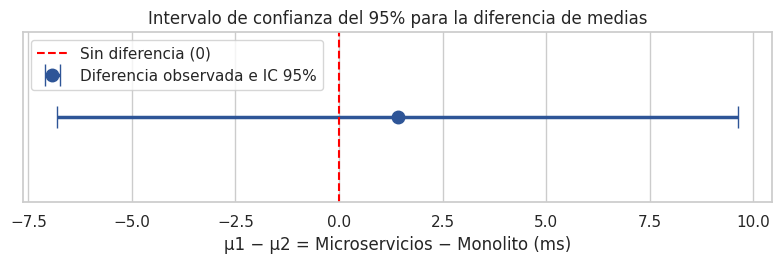

In [ ]:
# Visualización del IC de la diferencia
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.errorbar(diff, 0, xerr=[[diff - lo], [hi - diff]], fmt="o", color="#2E5597", capsize=8, lw=2.5, ms=9,
            label="Diferencia observada e IC 95%")
ax.axvline(0, color="red", ls="--", label="Sin diferencia (0)")
ax.set_yticks([])
ax.set_xlabel("μ1 − μ2 = Microservicios − Monolito (ms)")
ax.set_title("Intervalo de confianza del 95% para la diferencia de medias")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_ic_diferencia.png", dpi=150)
plt.show()

**IC para μ.** Con 95 % de confianza, la latencia media global se encuentra entre **119.8 y 128.0 ms**. Al aumentar la confianza el intervalo se ensancha (6.9 ms al 90 %, 8.2 ms al 95 % y 10.8 ms al 99 %): se gana certeza a costa de precisión. Los intervalos con t y con Z difieren en centésimas de ms, por lo que con N = 483 la elección no altera la conclusión, aunque t es la opción formalmente correcta cuando σ es desconocida.

**IC para μ₁ − μ₂.** La prueba de Levene (W = 1.84, p = 0.175 > 0.05) **no rechaza** la homogeneidad de varianzas, por lo que se usa el IC con varianza combinada (gl = 481). La diferencia observada es **+1.41 ms** (Microservicios − Monolito), con SE = 4.18 ms e **IC 95 % = (−6.80, 9.63) ms**; la corrección de Welch da prácticamente lo mismo (−6.80, 9.62), por lo que la conclusión no depende del método.

**¿0 ∈ IC?** Sí. El intervalo incluye el cero, así que los datos son compatibles con que **no exista diferencia** entre arquitecturas: no puede afirmarse, con 95 % de confianza, que una sea más lenta que la otra. En términos prácticos, la diferencia real podría ir desde una ventaja de ≈ 6.8 ms para microservicios hasta una penalización de ≈ 9.6 ms; si el SLA del sistema tolera un incremento de ~10 ms, incluso el peor caso plausible queda dentro de lo aceptable.

## Bloque 4 — Teoría de decisión (prueba de hipótesis)

### 4.1 Hipótesis (contextualizadas)
Como la pregunta de ingeniería es si microservicios **incrementa** la latencia, la prueba es **unilateral derecha**:

- **H₀:** μ_micro ≤ μ_mono — la arquitectura de microservicios **no** incrementa la latencia media respecto al monolito.
- **H₁:** μ_micro > μ_mono — la arquitectura de microservicios **sí incrementa** la latencia media (existe sobrecarga de red significativa).

### 4.2 Matriz de decisión y costos de error

In [ ]:
matriz = pd.DataFrame(
    {
        "H0 verdadera (microservicios NO es más lenta)": [
            "Decisión correcta: se mantiene la migración planeada.",
            "ERROR TIPO I (α): se concluye que microservicios es más lento cuando no lo es.",
        ],
        "H0 falsa (microservicios SÍ es más lenta)": [
            "ERROR TIPO II (β): no se detecta una degradación real de latencia.",
            "Decisión correcta: se detecta la sobrecarga y se actúa a tiempo.",
        ],
    },
    index=["No rechazar H0", "Rechazar H0"],
)
display(matriz.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

costos = pd.DataFrame({
    "Error": ["Tipo I (α)", "Tipo II (β)"],
    "Costo operativo / técnico": [
        "Falsa alarma: se frena, rediseña o revierte una arquitectura que en realidad no degrada el servicio; "
        "horas de ingeniería desperdiciadas, retraso del roadmap y descarte de beneficios reales de "
        "escalabilidad/despliegue independiente.",
        "Detección fallida: se despliega o mantiene una arquitectura con latencia mayor a la esperada; "
        "riesgo de incumplir SLAs, peor experiencia de usuario, mayor consumo de infraestructura y "
        "rediseño tardío y más caro en producción.",
    ],
})
display(costos.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,H0 verdadera (microservicios NO es más lenta),H0 falsa (microservicios SÍ es más lenta)
No rechazar H0,Decisión correcta: se mantiene la migración planeada.,ERROR TIPO II (β): no se detecta una degradación real de latencia.
Rechazar H0,ERROR TIPO I (α): se concluye que microservicios es más lento cuando no lo es.,Decisión correcta: se detecta la sobrecarga y se actúa a tiempo.


,Error,Costo operativo / técnico
0,Tipo I (α),"Falsa alarma: se frena, rediseña o revierte una arquitectura que en realidad no degrada el servicio; horas de ingeniería desperdiciadas, retraso del roadmap y descarte de beneficios reales de escalabilidad/despliegue independiente."
1,Tipo II (β),"Detección fallida: se despliega o mantiene una arquitectura con latencia mayor a la esperada; riesgo de incumplir SLAs, peor experiencia de usuario, mayor consumo de infraestructura y rediseño tardío y más caro en producción."


### 4.3 Nivel de significancia y 4.4 Prueba paramétrica
Se fija **α = 0.05**. Como la prueba de Levene (Bloque 3) define el supuesto de varianzas, se aplica `scipy.stats.ttest_ind` con `equal_var` consistente con ese resultado.

In [ ]:
resultado = stats.ttest_ind(x_micro, x_mono, equal_var=varianzas_iguales, alternative="greater")
resultado_2c = stats.ttest_ind(x_micro, x_mono, equal_var=varianzas_iguales, alternative="two-sided")
t_stat, p_val = resultado.statistic, resultado.pvalue
gl_t = resultado.df
t_crit = stats.t.ppf(1 - ALPHA, gl_t)

print(f"α = {ALPHA}")
print(f"Estadístico t = {t_stat:.4f} · gl = {gl_t:.1f}")
print(f"p-value (unilateral, H1: μ_micro > μ_mono) = {p_val:.4f}")
print(f"p-value (bilateral, referencia) = {resultado_2c.pvalue:.4f}")
print(f"Valor crítico t(0.95, {gl_t:.0f}) = {t_crit:.4f}")

rechaza = bool(p_val < ALPHA)
print("\nVEREDICTO:", "RECHAZAR H0" if rechaza else "NO RECHAZAR H0")

RES["prueba"] = {"alpha": ALPHA, "t": float(t_stat), "gl": float(gl_t), "p_unilateral": float(p_val),
                 "p_bilateral": float(resultado_2c.pvalue), "t_critico": float(t_crit), "rechaza_H0": rechaza}

α = 0.05
Estadístico t = 0.3384 · gl = 481.0
p-value (unilateral, H1: μ_micro > μ_mono) = 0.3676
p-value (bilateral, referencia) = 0.7352
Valor crítico t(0.95, 481) = 1.6480

VEREDICTO: NO RECHAZAR H0


### 4.5 Tamaño del efecto y riesgo de Error Tipo II (potencia)
Para que el veredicto sea interpretable en ingeniería se estima el tamaño del efecto (d de Cohen) y la **potencia** (1 − β) de la prueba para detectar una diferencia técnicamente relevante.

In [ ]:
n1, n2 = len(x_micro), len(x_mono)
sp = np.sqrt(((n1 - 1) * x_micro.var(ddof=1) + (n2 - 1) * x_mono.var(ddof=1)) / (n1 + n2 - 2))
d_cohen = diff / sp


def potencia_unilateral(delta, sd, n1, n2, alfa=0.05):
    """Potencia de la t de dos muestras (cola derecha) vía distribución t no central."""
    gl_ = n1 + n2 - 2
    ncp = (delta / sd) * np.sqrt(n1 * n2 / (n1 + n2))
    tcrit = stats.t.ppf(1 - alfa, gl_)
    return 1 - stats.nct.cdf(tcrit, gl_, ncp)


def n_por_grupo(delta, sd, objetivo=0.80, alfa=0.05):
    n_ = 2
    while potencia_unilateral(delta, sd, n_, n_, alfa) < objetivo:
        n_ += 1
    return n_


DELTA_RELEVANTE = 10.0  # ms: diferencia que se considera técnicamente relevante (supuesto del equipo)
pot_obs = potencia_unilateral(diff, sp, n1, n2, ALPHA)
pot_rel = potencia_unilateral(DELTA_RELEVANTE, sp, n1, n2, ALPHA)
n_req = n_por_grupo(DELTA_RELEVANTE, sp)
n_req_obs = n_por_grupo(abs(diff), sp) if diff > 0 else None

print(f"Desv. estándar combinada (sp) = {sp:.3f} ms")
print(f"d de Cohen = {d_cohen:.3f}")
print(f"Potencia para el efecto observado ({diff:.2f} ms): {pot_obs:.3f}  → β ≈ {1 - pot_obs:.3f}")
print(f"Potencia para Δ = {DELTA_RELEVANTE:.0f} ms con n = {n1}/{n2}: {pot_rel:.3f}  → β ≈ {1 - pot_rel:.3f}")
print(f"n por grupo para 80% de potencia con Δ = {DELTA_RELEVANTE:.0f} ms: {n_req}")
if n_req_obs:
    print(f"n por grupo para 80% de potencia con el efecto observado: {n_req_obs}")

# Como el dataset es sintético se conocen las medias teóricas del generador (media Gamma = shape·scale + desplazamiento)
DELTA_TEORICO = (2.2 * 40 + 45) - (2.5 * 35 + 40)   # 133.0 − 127.5 = 5.5 ms
pot_teorico = potencia_unilateral(DELTA_TEORICO, sp, n1, n2, ALPHA)
n_req_teorico = n_por_grupo(DELTA_TEORICO, sp)
print(f"\nDiferencia teórica del generador sintético: {DELTA_TEORICO:.1f} ms")
print(f"Potencia de la prueba para ese efecto con n = {n1}/{n2}: {pot_teorico:.3f}  → β ≈ {1 - pot_teorico:.3f}")
print(f"n por grupo para 80% de potencia con ese efecto: {n_req_teorico}")

RES["efecto"] = {"delta_teorico": DELTA_TEORICO, "potencia_teorico": float(pot_teorico),
                 "n_req_teorico": int(n_req_teorico),
                 "sp": float(sp), "d": float(d_cohen), "potencia_obs": float(pot_obs),
                 "delta_relevante": DELTA_RELEVANTE, "potencia_relevante": float(pot_rel),
                 "n_req_relevante": int(n_req), "n_req_obs": int(n_req_obs) if n_req_obs else None}

Desv. estándar combinada (sp) = 45.941 ms
d de Cohen = 0.031
Potencia para el efecto observado (1.41 ms): 0.096  → β ≈ 0.904
Potencia para Δ = 10 ms con n = 243/240: 0.771  → β ≈ 0.229
n por grupo para 80% de potencia con Δ = 10 ms: 262
n por grupo para 80% de potencia con el efecto observado: 13040

Diferencia teórica del generador sintético: 5.5 ms
Potencia de la prueba para ese efecto con n = 243/240: 0.370  → β ≈ 0.630
n por grupo para 80% de potencia con ese efecto: 864


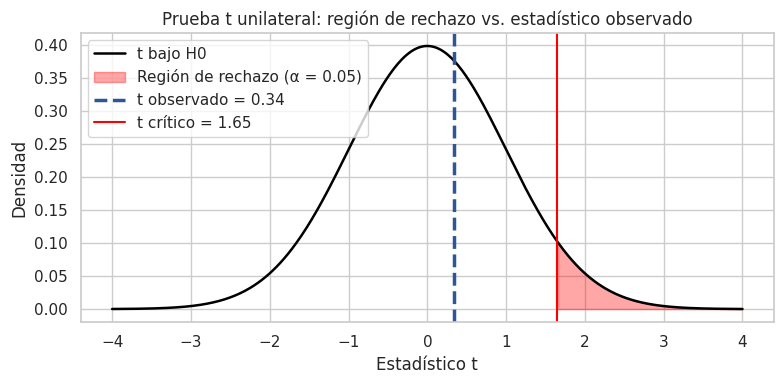

In [ ]:
# Visualización de la regla de decisión
gl_plot = gl_t
xs = np.linspace(-4, 4, 500)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(xs, stats.t.pdf(xs, gl_plot), color="black", lw=1.8, label="t bajo H0")
ax.fill_between(xs, stats.t.pdf(xs, gl_plot), where=xs >= t_crit, color="red", alpha=0.35,
                label=f"Región de rechazo (α = {ALPHA})")
ax.axvline(t_stat, color="#2E5597", lw=2.5, ls="--", label=f"t observado = {t_stat:.2f}")
ax.axvline(t_crit, color="red", lw=1.5, label=f"t crítico = {t_crit:.2f}")
ax.set_xlabel("Estadístico t")
ax.set_ylabel("Densidad")
ax.set_title("Prueba t unilateral: región de rechazo vs. estadístico observado")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_region_rechazo.png", dpi=150)
plt.show()

**Veredicto: NO RECHAZAR H₀.** El estadístico t = 0.338 (gl = 481) es menor que el valor crítico 1.648, y el p-value unilateral = 0.368 es mayor que α = 0.05 (p bilateral = 0.735). No existe evidencia estadística suficiente de que la arquitectura de microservicios incremente la latencia media respecto al monolito. El resultado es coherente con el IC del Bloque 3 (0 ∈ IC).

**Tamaño del efecto y Error Tipo II.** El d de Cohen es 0.03 (efecto despreciable). Sin embargo, *no rechazar H₀ no demuestra que no haya diferencia*. Con ≈ 240 observaciones por grupo la prueba tiene una potencia de 0.77 para detectar un incremento de 10 ms (β ≈ 0.23), pero solo de 0.37 para un incremento de 5.5 ms. Dado que los datos son sintéticos, se conocen las medias teóricas del generador (127.5 ms y 133.0 ms): existe una diferencia real de 5.5 ms que la muestra **no logró detectar**, lo cual ilustra un Error Tipo II ocasionado por la baja potencia ante efectos pequeños y la alta variabilidad (s ≈ 46 ms). Detectar 5.5 ms con 80 % de potencia requeriría ≈ 864 observaciones por grupo.

**Recomendación técnica de ingeniería.**
1. Con los datos disponibles, la migración a microservicios **no muestra una penalización significativa de latencia**; el costo de red adicional, si existe, es como máximo de ≈ 10 ms (extremo superior del IC), por lo que no constituye por sí solo una razón técnica para descartar la arquitectura.
2. Antes de comprometer SLAs estrictos (< 10 ms de margen), ampliar la muestra con pruebas de carga reales (Locust / Apache Bench) hasta ≈ 900 mediciones por grupo, y comparar también percentiles altos (p95/p99), no solo la media, pues la distribución tiene cola derecha.
3. Mitigar proactivamente la sobrecarga de red típica de microservicios (comunicación gRPC, caché en el gateway, agrupación de llamadas entre servicios) y mantener monitoreo continuo de latencia.

## Conclusión general y guardado de resultados

In [ ]:
with open(ROOT / "docs" / "resultados.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=2)
print("Resultados guardados en docs/resultados.json")

Resultados guardados en docs/resultados.json


**Conclusión general.** Se analizaron 483 observaciones depuradas de latencia (240 Monolito, 243 Microservicios). Ambas distribuciones son asimétricas a la derecha y muy similares (medias 123.2 y 124.6 ms). La simulación del TCL confirmó que σ_x̄ = s/√n y la convergencia hacia la normalidad; el IC al 95 % para la media global fue (119.8, 128.0) ms y el de la diferencia de medias (−6.80, 9.63) ms, que contiene al cero. La prueba t unilateral (t = 0.338; p = 0.368) **no rechaza H₀** con α = 0.05: no hay evidencia de que microservicios incremente la latencia. Se advierte que la potencia de la prueba es limitada para efectos pequeños (≈ 5 ms), por lo que se recomienda ampliar la muestra antes de fijar SLAs estrictos.